In [ ]:
# ============================================================
# TALLER DE INTEGRACIÓN Y DIFERENCIACIÓN NUMÉRICA
# Ejercicio 2 - Datos experimentales
# Python con NumPy y SciPy
#
# Jimmy Alexander Calderon Trujillo
# Sebastian Barahona
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import trapezoid, simpson

# ------------------------------------------------------------
# 1. CARGA DE LOS DATOS EXPERIMENTALES
# ------------------------------------------------------------

datos = np.loadtxt(
    "../../datos/datos_sensor.csv",
    delimiter=",",
    skiprows=1
)

x = datos[:, 0]
y = datos[:, 1]

N = len(x)

# ------------------------------------------------------------
# 2. VERIFICACIÓN DE LOS DATOS
# ------------------------------------------------------------

dx = np.diff(x)
h = dx[0]

print("EJERCICIO 2 - DATOS EXPERIMENTALES")
print("---------------------------------------------")
print(f"Número de mediciones : {N}")
print(f"x inicial            : {x[0]:.1f}")
print(f"x final              : {x[-1]:.1f}")
print(f"Espaciado h          : {h:.1f}")
print(f"Espaciado uniforme   : {'SI' if np.allclose(dx, h) else 'NO'}")
print(f"Datos faltantes      : {'SI' if np.isnan(datos).any() else 'NO'}")

EJERCICIO 2 - DATOS EXPERIMENTALES
---------------------------------------------
Número de mediciones : 50
x inicial            : 0.0
x final              : 9.8
Espaciado h          : 0.2
Espaciado uniforme   : SI
Datos faltantes      : NO


In [3]:
# ============================================================
# INTEGRACIÓN NUMÉRICA DE LOS DATOS CON SCIPY
# ============================================================

# Regla del trapecio sobre las 50 mediciones
I_trap = trapezoid(y, x=x)

# Simpson de SciPy sobre las 50 mediciones
I_simpson_scipy = simpson(y, x=x)

# ------------------------------------------------------------
# Simpson 1/3 clásico + trapecio en el último intervalo
# ------------------------------------------------------------
#
# 50 puntos producen 49 subintervalos.
# Simpson 1/3 compuesto clásico requiere un número par
# de subintervalos.
#
# Por eso aplicamos Simpson a los primeros 49 puntos
# (48 subintervalos) y trapecio al último intervalo.

I_simpson_parcial = simpson(y[:49], x=x[:49])

I_ultimo_trap = trapezoid(y[48:50], x=x[48:50])

I_metodo_mixto = I_simpson_parcial + I_ultimo_trap

# ------------------------------------------------------------
# RESULTADOS
# ------------------------------------------------------------

print("INTEGRACIÓN NUMÉRICA CON SCIPY")
print("---------------------------------------------")
print(f"Trapecio SciPy          : {I_trap:.12f}")
print(f"Simpson SciPy completo  : {I_simpson_scipy:.12f}")
print(f"Simpson [0,9.6]         : {I_simpson_parcial:.12f}")
print(f"Trapecio [9.6,9.8]      : {I_ultimo_trap:.12f}")
print(f"Método mixto total      : {I_metodo_mixto:.12f}")

INTEGRACIÓN NUMÉRICA CON SCIPY
---------------------------------------------
Trapecio SciPy          : 21.190846339900
Simpson SciPy completo  : 21.192113098332
Simpson [0,9.6]         : 20.698381760973
Trapecio [9.6,9.8]      : 0.493571183340
Método mixto total      : 21.191952944313


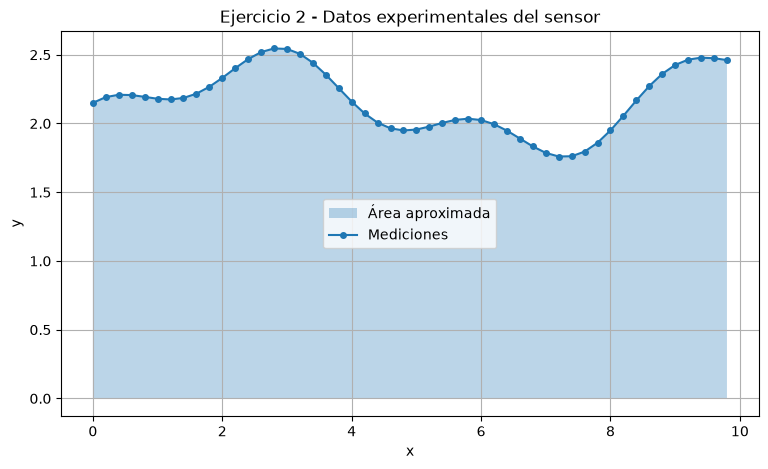

In [4]:
# ============================================================
# GRÁFICA DE LOS DATOS EXPERIMENTALES
# ============================================================

plt.figure(figsize=(9, 5))

# Área aproximada
plt.fill_between(
    x,
    y,
    alpha=0.3,
    label="Área aproximada"
)

# Mediciones experimentales
plt.plot(
    x,
    y,
    "o-",
    linewidth=1.5,
    markersize=4,
    label="Mediciones"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Ejercicio 2 - Datos experimentales del sensor")

plt.grid(True)
plt.legend()

plt.show()